# SwiftRoute Logistics - Delivery Delay Prediction
## DSAI Mini Coursework

**Student name**: *Hoàng Văn Lập*  
**Email**: *laphv494@gmail.com*  
**Discord username**: *schaffen49*  
**Submission date**: *22/10/2026*

---

### Mark Scheme

| Section | Marks |
|---|---|
| 1 | 10 |
| 2 | 3 |
| 3 | 10 |
| 4 | 12 |
| 5 | 15 |
| 6 | 15 |
| 7 | 8 |
| 8 | 12 |
| 9 | 5 |
| Extension | 10 |
| **Total** | **100** |

---
# SECTION 1 - Understanding the Problem *(10 marks)*

**1.1** *(1 mark)* In one sentence, describe what SwiftRoute is trying to predict and why it matters.

*SwiftRoute Logistics wants to predict shipment delays at pickup so it can take early action to avoid SLA violation, late deliveries, financial penalties, unhappy customers, and lost business opportunities.*

---

**1.2** *(2 marks)* Is this a classification or regression problem? What is the target variable? What does one row in the training data represent?

*This is a classification problem with the target variable is is_delayed (0 or 1) representing whether a shipment will be delayed. Each row in the training data represents a single shipment with its associated features.*

---

**1.3** *(3 marks)* Only ~12% of shipments are delayed. Explain why **accuracy** is a misleading metric here. What metric will you use instead, and what does it measure in the context of delivery operations?

*Accuracy is misleading because the dataset is imbalanced (88% on-time vs. 12% delayed), so a model can achieve 88% accuracy by predicting every shipment as on-time while failing to detect any actual delays.*

Instead of accuracy, we can use metrics above:
- `ROC-AUC`: Measures the model's ability to distinguish between delayed and on-time shipments across all classification thresholds.

---

**1.4** *(2 marks)* The Operations team can only intervene on the top **15%** of highest-risk shipments. Describe the two types of mistake your model can make, and explain which is more costly to SwiftRoute.

- False Positive (FP): The model predicts a shipment will be delayed, but it arrives on time, wasting intervention resources.
- False Negative (FN): The model predicts a shipment will arrive on time, but it is delayed, causing potential SLA penalties and customer dissatisfaction. FN is generally more costly to SwiftRoute.

---

**1.5** *(2 marks)* The `weather_events` table stores disruptions as date ranges (start_date to end_date) by region. Explain the challenge of joining this to `shipments`, and what logic is needed.

*The challenge is that weather events cover date ranges, while each shipment has a single pickup date. To merge the data, we check whether the pickup date falls within a weather event's date range and whether the event affects the origin or destination region. We then create a single indicator showing whether each shipment is affected by a weather event.*

---
# SECTION 2 - Setup & Data Loading *(3 marks)*

In [82]:
# *(1 mark)* Import libraries
import warnings; warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42

In [83]:
# *(2 marks)* Load all four CSV files. Print shape and first few rows of each.
shipments = pd.read_csv('data/shipments.csv', parse_dates=['pickup_date'])
routes    = pd.read_csv('data/routes.csv')
carriers  = pd.read_csv('data/carriers.csv')
weather   = pd.read_csv('data/weather_events.csv', parse_dates=['start_date','end_date'])

# Your code here
print("Shipments shape:", shipments.shape)
display(shipments.head())
print("Routes shape:", routes.shape)
display(routes.head())
print("Carriers shape:", carriers.shape)
display(carriers.head())
print("Weather shape:", weather.shape)
display(weather.head())

Shipments shape: (10025, 12)


,shipment_id,pickup_date,origin_region,dest_region,service_tier,carrier_id,route_id,weight_kg,volume_cm3,declared_value,is_business,is_delayed
0,SH0000001,2025-09-26,London,North_West,economy,C03,R0038,11.54,9427,5.44,0,0
1,SH0000002,2024-12-09,North_West,North_East,standard,C01,R0044,9.26,9864,7.48,1,0
2,SH0000003,2025-11-15,South_East,South_West,express,C05,R0013,0.43,96,37.44,0,0
3,SH0000004,2025-06-12,South_East,North_East,express,C08,R0009,8.84,6541,141.25,0,1
4,SH0000005,2026-03-21,Yorkshire,Scotland,standard,C04,R0010,11.10,4959,148.71,0,0


Routes shape: (60, 7)


,route_id,origin_region,dest_region,distance_km,n_depot_hops,historical_delay_rate,avg_transit_days
0,R0001,London,North_East,480,3,0.2471,2.92
1,R0002,Scotland,Yorkshire,139,1,0.1617,1.85
2,R0003,South_West,Midlands,191,1,0.1449,1.71
3,R0004,London,South_East,127,1,0.0450,1.85
4,R0005,Midlands,North_East,279,2,0.0970,1.96


Carriers shape: (8, 7)


,carrier_id,carrier_name,tier_coverage,reliability_score,capacity_utilisation,avg_delay_mins,n_active_routes
0,C01,FastTrack,all,0.9508,0.5926,78.2,17
1,C02,PrimeMove,all,0.9049,0.6838,82.2,25
2,C03,SureDeliver,all,0.8605,0.6675,35.0,8
3,C04,QuickHaul,all,0.8332,0.7361,29.7,11
4,C05,NorthernPost,express_only,0.7640,0.8150,34.9,15


Weather shape: (265, 6)


,event_id,region,event_type,severity,start_date,end_date
0,W00001,Midlands,high_wind,2,2024-01-03,2024-01-05
1,W00002,Yorkshire,snow,1,2024-01-26,2024-01-30
2,W00003,London,flood,1,2024-01-15,2024-01-18
3,W00004,North_East,high_wind,1,2024-01-26,2024-02-01
4,W00005,North_West,storm,2,2024-01-24,2024-01-26


---
# SECTION 3 - Exploring the Data (EDA) *(10 marks)*

### 3.1 Data Quality Check *(3 marks)*

In [84]:
# *(3 marks)* Check: dtypes, null counts, duplicates, referential integrity,
# and the overall delay rate.

# Your code here
# Check dtypes
print("Shipments dtypes:\n") 
display(shipments.dtypes)
print("Routes dtypes:\n")
display(routes.dtypes)
print("Carriers dtypes:\n")
display(carriers.dtypes)
print("Weather dtypes:\n")
display(weather.dtypes)


Shipments dtypes:



shipment_id                  str
pickup_date       datetime64[us]
origin_region                str
dest_region                  str
service_tier                 str
carrier_id                   str
route_id                     str
weight_kg                float64
volume_cm3                 int64
declared_value           float64
is_business                int64
is_delayed                 int64
dtype: object

Routes dtypes:



route_id                     str
origin_region                str
dest_region                  str
distance_km                int64
n_depot_hops               int64
historical_delay_rate    float64
avg_transit_days         float64
dtype: object

Carriers dtypes:



carrier_id                  str
carrier_name                str
tier_coverage               str
reliability_score       float64
capacity_utilisation    float64
avg_delay_mins          float64
n_active_routes           int64
dtype: object

Weather dtypes:



event_id                 str
region                   str
event_type               str
severity               int64
start_date    datetime64[us]
end_date      datetime64[us]
dtype: object

In [85]:
# Check for null values                           
print("Shipments null counts:\n")
display(shipments.isnull().sum())
print("Routes null counts:\n")
display(routes.isnull().sum())
print("Carriers null counts:\n")
display(carriers.isnull().sum())
print("Weather null counts:\n")
display(weather.isnull().sum())

Shipments null counts:



shipment_id         0
pickup_date         0
origin_region       0
dest_region         0
service_tier        0
carrier_id          0
route_id            0
weight_kg         320
volume_cm3          0
declared_value    507
is_business         0
is_delayed          0
dtype: int64

Routes null counts:



route_id                 0
origin_region            0
dest_region              0
distance_km              0
n_depot_hops             0
historical_delay_rate    0
avg_transit_days         0
dtype: int64

Carriers null counts:



carrier_id              0
carrier_name            0
tier_coverage           0
reliability_score       0
capacity_utilisation    0
avg_delay_mins          0
n_active_routes         0
dtype: int64

Weather null counts:



event_id      0
region        0
event_type    0
severity      0
start_date    0
end_date      0
dtype: int64

In [86]:
cols = ["weight_kg", "declared_value"]

missing_report = pd.DataFrame({
    "Missing Count": shipments[cols].isna().sum(),
    "Missing (%)": shipments[cols].isna().mean() * 100,

    "Delayed Count": [
        shipments.loc[shipments[col].isna(), "is_delayed"].eq(1).sum()
        for col in cols
    ],

    "Delayed Rate (%)": [
        shipments.loc[shipments[col].isna(), "is_delayed"].eq(1).mean() * 100
        for col in cols
    ]
}).round(2)

display(missing_report)

,Missing Count,Missing (%),Delayed Count,Delayed Rate (%)
weight_kg,320,3.19,35,10.94
declared_value,507,5.06,75,14.79


In [87]:
# Check for duplicate values
print("Shipments duplicates:", shipments.duplicated().sum())
print("Routes duplicates:", routes.duplicated().sum())
print("Carriers duplicates:", carriers.duplicated().sum())
print("Weather duplicates:", weather.duplicated().sum())

Shipments duplicates: 0
Routes duplicates: 0
Carriers duplicates: 0
Weather duplicates: 0


In [88]:
shipments_check = shipments.drop(columns=['shipment_id'])
print("Duplicate shipments:", shipments_check.duplicated().sum())
carriers_check = carriers.drop(columns=['carrier_id'])
print("Duplicate carriers:", carriers_check.duplicated().sum())
routes_check = routes.drop(columns=['route_id'])
print("Duplicate routes:", routes_check.duplicated().sum())

Duplicate shipments: 25
Duplicate carriers: 0
Duplicate routes: 0


In [89]:
# check integrity of shipments -> carriers
num_valid_carriers = shipments["carrier_id"].isin(carriers["carrier_id"]).count()

print("Number of valid carrier IDs in shipments:", num_valid_carriers)
print("Percentage of valid carrier IDs:", (num_valid_carriers / len(shipments["carrier_id"])) * 100,"%")

# check integrity of shipments -> routes
num_valid_routes = shipments["route_id"].isin(routes["route_id"]).count()

print("Number of valid route IDs in shipments:", num_valid_routes)
print("Percentage of valid route IDs:", (num_valid_routes / len(shipments["route_id"])) * 100,"%")

Number of valid carrier IDs in shipments: 10025
Percentage of valid carrier IDs: 100.0 %
Number of valid route IDs in shipments: 10025
Percentage of valid route IDs: 100.0 %


In [90]:
print('Overall delay rate: {:.2%}'.format(shipments.is_delayed.mean()))

Overall delay rate: 11.91%


**Commentary** - List quality issues and how you will handle each.

- **Missing values:** The `shipments` table contains missing values in the `weight_kg` and `declared_value` columns. We use median imputation based on the training data within each fold of k-fold cross-validation to handle missing values and prevent data leakage.
- **Duplicate rows:** The `shipments` table contains 25 duplicate rows. We remove the duplicates, keeping only the first occurrence of each duplicated row.

### 3.2 Distribution of Key Columns *(2 marks)*

In [91]:
# *(2 marks)* Plot: service_tier mix, weight distribution, delay rate over time
# (monthly), carrier reliability scores, route distance distribution.

# Your code here

In [92]:

import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

def plot_monthly_delay(shipments, ax):
    monthly = (
        shipments.groupby(shipments.pickup_date.dt.to_period('M'))['is_delayed']
        .mean()
    )
    monthly.index = monthly.index.to_timestamp()

    ax.plot(monthly.index, monthly.values, color='steelblue', marker='o', markersize=3)
    ax.set(title='Monthly delay rate', ylabel='Delay rate', xlabel='')
    ax.set_xlim(monthly.index.min(), monthly.index.max())

    # Hien thi 1/YYYY tai thang 1, cac thang khac chi hien so
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(FuncFormatter(
        lambda x, _: f'1/{mdates.num2date(x).year}'
        if mdates.num2date(x).month == 1
        else str(mdates.num2date(x).month)
    ))
    ax.tick_params(axis='x', rotation=90, labelsize=7)

    # Danh dau thang 1 moi nam
    for date, value in monthly.items():
        if date.month == 1:
            ax.vlines(date, ax.get_ylim()[0], value,
                      colors='gray', linestyles='--', alpha=0.7)
            ax.scatter(date, value, color='red', s=30, zorder=5)

    ax.grid(axis='y', linestyle=':', alpha=0.3)


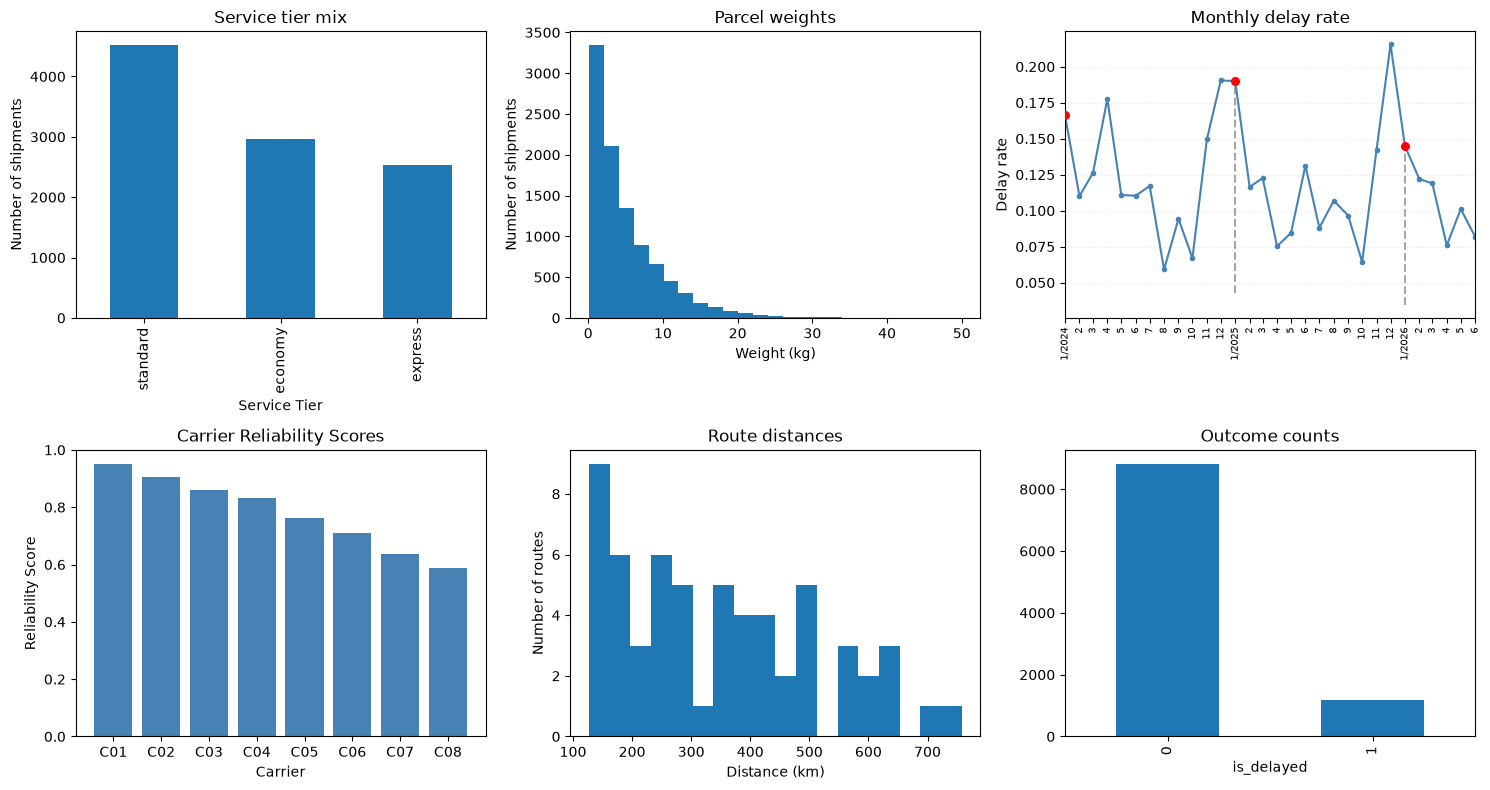

In [93]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))

# Service tier mix
shipments.service_tier.value_counts().plot.bar(
    ax=ax[0,0], title='Service tier mix',
    xlabel = 'Service Tier',
    ylabel='Number of shipments'
)

# Weight distribution
ax[0,1].hist(shipments.weight_kg.dropna(), bins=25)
ax[0,1].set(title='Parcel weights', xlabel='Weight (kg)',
            ylabel='Number of shipments')

# Monthly delay rate
plot_monthly_delay(shipments, ax[0,2])

carrier_scores = carriers.sort_values(
    'reliability_score', ascending=False
)

ax[1,0].bar(
    carrier_scores['carrier_id'],
    carrier_scores['reliability_score'],
    color='steelblue'
)

ax[1,0].set(
    title='Carrier Reliability Scores',
    xlabel='Carrier',
    ylabel='Reliability Score',
    ylim=(0, 1)
)

ax[1,1].hist(routes.distance_km, bins=18)
ax[1,1].set_title('Route distances')
ax[1,1].set_xlabel('Distance (km)')
ax[1,1].set_ylabel('Number of routes')

shipments.is_delayed.value_counts().sort_index().plot.bar(ax=ax[1,2],title='Outcome counts')


plt.tight_layout()
plt.show()

**Commentary** - Two interesting observations.

- **Delivery delays:** Delays increase in December and January, possibly due to holiday shipping demand and winter weather conditions.
  
- **Parcel weight:** Most shipments weigh less than 10 kg, with only a few heavy parcels.
  
- **Carrier reliability:** Scores range from 0.59 to 0.95, showing differences in carrier performance that may help predict delays.

### 3.3 Which Factors Are Related to Delays? *(3 marks)*

In [94]:
# *(3 marks)* Explore delay rate vs:
# - service_tier
# - carrier (join to carriers.csv for reliability_score)
# - route distance (join to routes.csv)
# - weather (do shipments during weather events delay more?)

# Your code here
merge = shipments.merge(carriers, on='carrier_id', how='left')
merge = merge.merge(
    routes.drop(columns=['origin_region', 'dest_region']),
    on='route_id', how='left'
)

# Convert date columns
merge['pickup_date'] = pd.to_datetime(merge['pickup_date'])
weather = weather.copy()
weather['start_date'] = pd.to_datetime(weather['start_date'])
weather['end_date'] = pd.to_datetime(weather['end_date'])

# Match weather events by date and region
merge['origin_weather'] = False
merge['dest_weather'] = False
merge['weather_severity'] = 0

for event in weather.itertuples(index=False):
    in_date = merge['pickup_date'].between(
        event.start_date, event.end_date
    )

    origin = in_date & merge['origin_region'].eq(event.region)
    dest = in_date & merge['dest_region'].eq(event.region)

    merge['origin_weather'] |= origin
    merge['dest_weather'] |= dest

    matched = origin | dest
    merge.loc[matched, 'weather_severity'] = np.maximum(
        merge.loc[matched, 'weather_severity'],
        event.severity
    )

# Combined weather indicator
merge['weather_affected'] = (
    merge['origin_weather'] | merge['dest_weather']
)

merge

,shipment_id,pickup_date,origin_region,dest_region,service_tier,carrier_id,route_id,weight_kg,volume_cm3,declared_value,...,avg_delay_mins,n_active_routes,distance_km,n_depot_hops,historical_delay_rate,avg_transit_days,origin_weather,dest_weather,weather_severity,weather_affected
0,SH0000001,2025-09-26,London,North_West,economy,C03,R0038,11.54,9427,5.44,...,35.0,8,438,3,0.1999,2.69,False,True,1,True
1,SH0000002,2024-12-09,North_West,North_East,standard,C01,R0044,9.26,9864,7.48,...,78.2,17,159,1,0.0944,1.68,False,False,0,False
2,SH0000003,2025-11-15,South_East,South_West,express,C05,R0013,0.43,96,37.44,...,34.9,15,180,1,0.0998,1.99,False,False,0,False
3,SH0000004,2025-06-12,South_East,North_East,express,C08,R0009,8.84,6541,141.25,...,90.0,11,433,3,0.1825,2.61,True,False,3,True
4,SH0000005,2026-03-21,Yorkshire,Scotland,standard,C04,R0010,11.10,4959,148.71,...,29.7,11,153,1,0.1086,1.55,False,False,0,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10020,SH0010021,2024-01-17,Midlands,London,standard,C02,R0053,1.31,345,140.66,...,82.2,25,348,2,0.1542,2.48,False,True,1,True
10021,SH0010022,2025-04-23,North_West,London,express,C01,R0057,3.61,3306,83.74,...,78.2,17,393,2,0.1576,2.32,False,False,0,False
10022,SH0010023,2024-05-29,South_East,North_West,standard,C03,R0056,8.86,9360,29.94,...,35.0,8,295,2,0.1647,2.32,False,False,0,False
10023,SH0010024,2024-10-08,South_East,Wales,express,C03,R0048,2.66,784,5.16,...,35.0,8,615,3,0.2325,3.38,False,False,0,False


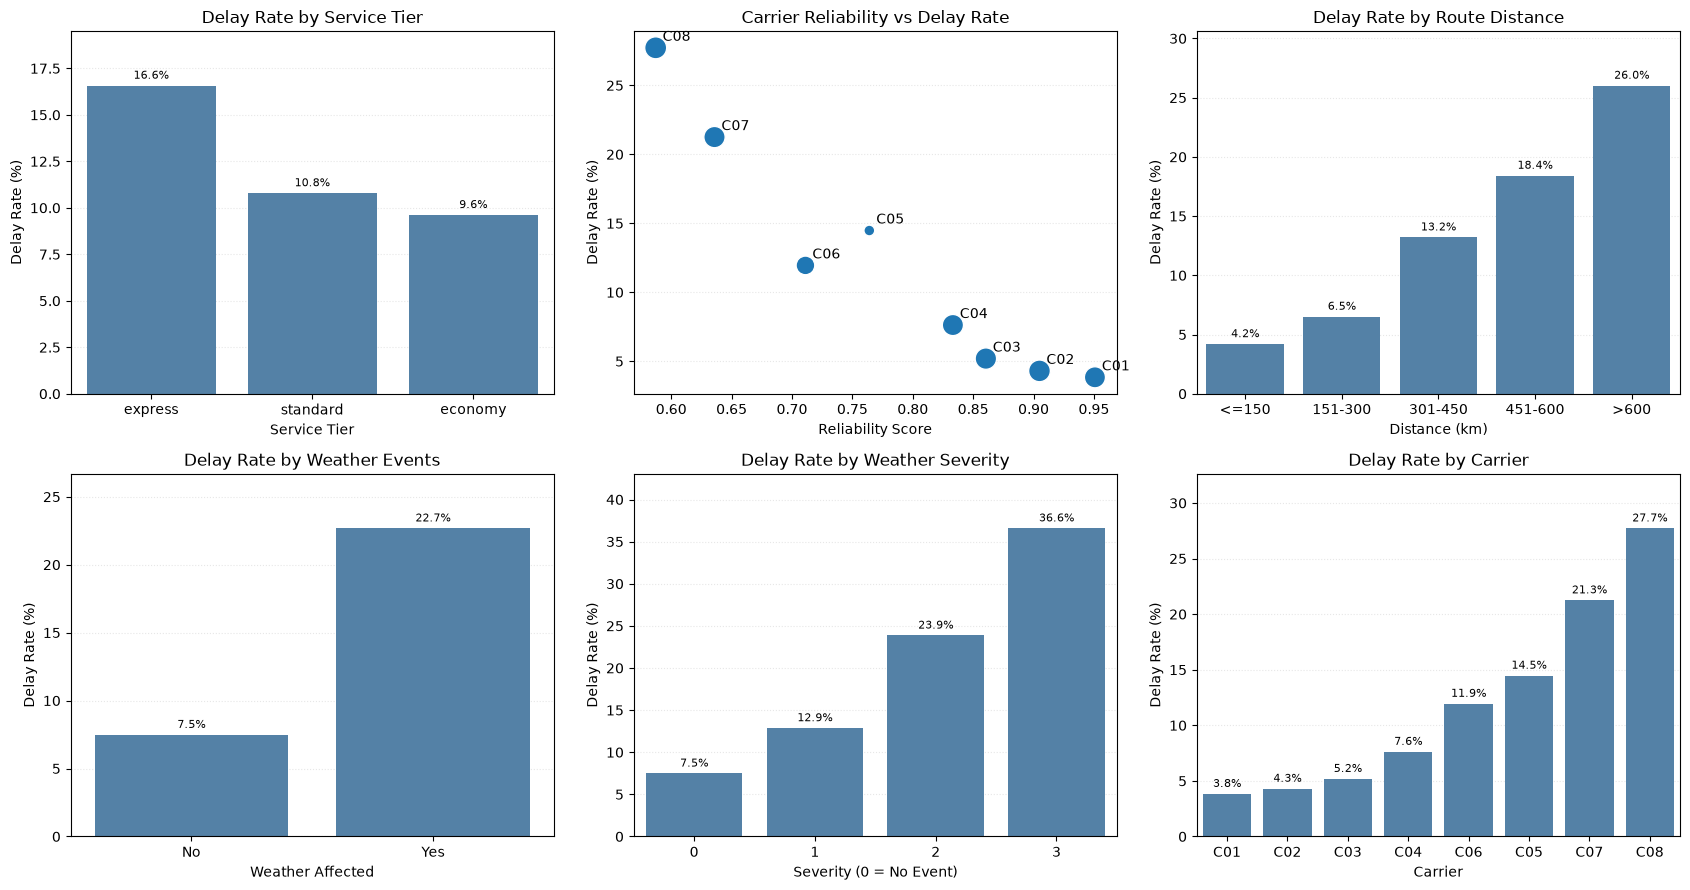

In [95]:
df = merge.copy()

# Create distance groups
df['distance_band'] = pd.cut(
    df['distance_km'],
    bins=[0, 150, 300, 450, 600, np.inf],
    labels=['<=150', '151-300', '301-450', '451-600', '>600']
)

# Calculate delay rate (%)
def delay_rate(column):
    return df.groupby(column, observed=True)['is_delayed'].mean() * 100

fig, ax = plt.subplots(2, 3, figsize=(17, 9))

# 1. Delay Rate by Service Tier
tier = delay_rate('service_tier').sort_values(ascending=False)
sns.barplot(x=tier.index, y=tier.values, ax=ax[0,0], color='steelblue')
ax[0,0].set(
    title='Delay Rate by Service Tier',
    xlabel='Service Tier',
    ylabel='Delay Rate (%)'
)

# 2. Carrier Reliability vs Delay Rate
carrier = (
    df.groupby(['carrier_id', 'reliability_score'])['is_delayed']
    .agg(delay_rate='mean', count='size')
    .reset_index()
)
carrier['delay_rate'] *= 100

sns.scatterplot(
    data=carrier,
    x='reliability_score',
    y='delay_rate',
    size='count',
    sizes=(60, 250),
    legend=False,
    ax=ax[0,1]
)

for row in carrier.itertuples():
    ax[0,1].annotate(
        row.carrier_id,
        (row.reliability_score, row.delay_rate),
        xytext=(5, 5),
        textcoords='offset points'
    )

ax[0,1].set(
    title='Carrier Reliability vs Delay Rate',
    xlabel='Reliability Score',
    ylabel='Delay Rate (%)'
)

# 3. Delay Rate by Route Distance
distance = delay_rate('distance_band')
sns.barplot(
    x=distance.index.astype(str),
    y=distance.values,
    ax=ax[0,2],
    color='steelblue'
)
ax[0,2].set(
    title='Delay Rate by Route Distance',
    xlabel='Distance (km)',
    ylabel='Delay Rate (%)'
)

# 4. Delay Rate by Weather Impact
weather_affected = delay_rate('weather_affected')
sns.barplot(
    x=weather_affected.index.astype(str),
    y=weather_affected.values,
    ax=ax[1,0],
    color='steelblue'
)
ax[1,0].set(
    title='Delay Rate by Weather Events',
    xlabel='Weather Affected',
    ylabel='Delay Rate (%)'
)
ax[1,0].set_xticks(range(len(weather_affected)))
ax[1,0].set_xticklabels(
    ['No' if x == False else 'Yes' for x in weather_affected.index]
)

# 5. Delay Rate by Weather Severity
severity = delay_rate('weather_severity')
sns.barplot(
    x=severity.index.astype(str),
    y=severity.values,
    ax=ax[1,1],
    color='steelblue'
)
ax[1,1].set(
    title='Delay Rate by Weather Severity',
    xlabel='Severity (0 = No Event)',
    ylabel='Delay Rate (%)'
)

# 6. Delay Rate by Carrier
carrier_rates = delay_rate('carrier_id').sort_values()
sns.barplot(
    x=carrier_rates.index,
    y=carrier_rates.values,
    ax=ax[1,2],
    color='steelblue'
)
ax[1,2].set(
    title='Delay Rate by Carrier',
    xlabel='Carrier',
    ylabel='Delay Rate (%)'
)

# Add values above bars
for axis in [ax[0,0], ax[0,2], ax[1,0], ax[1,1], ax[1,2]]:
    for bar in axis.patches:
        height = bar.get_height()
        axis.annotate(
            f'{height:.1f}%',
            (bar.get_x() + bar.get_width()/2, height),
            ha='center',
            va='bottom',
            fontsize=8,
            xytext=(0, 3),
            textcoords='offset points'
        )
    axis.set_ylim(0, axis.get_ylim()[1] * 1.12)

for axis in ax.flat:
    axis.grid(axis='y', linestyle=':', alpha=0.3)
    axis.set_axisbelow(True)

plt.tight_layout()
plt.show()


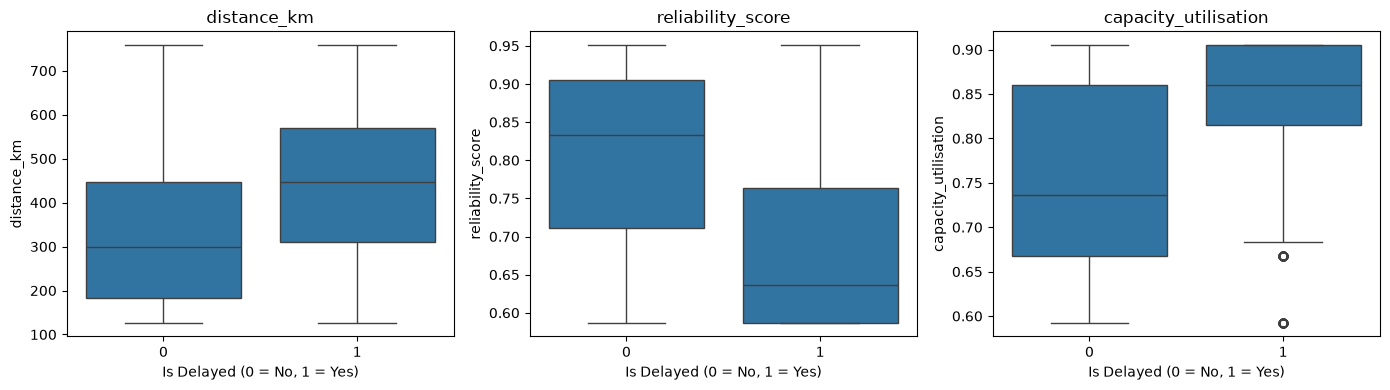

In [96]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))

features = [
    'distance_km',
    'reliability_score',
    'capacity_utilisation'
]

for a, feature in zip(ax, features):
    sns.boxplot(data=merge, x='is_delayed', y=feature, ax=a)
    a.set_title(feature)
    a.set_xlabel('Is Delayed (0 = No, 1 = Yes)')

plt.tight_layout()
plt.show()


**Commentary** - Which factors show the strongest relationship with delays?

Factors Showing the Strongest Relationship with Delivery Delays:
- `Weather Disruptions`: Shipments affected by weather events have significantly higher delay rates than unaffected shipments.
  
- `Weather Severity`: Delay rates increase as weather severity becomes higher.
  
- `Carrier Reliability`: Carriers with higher reliability scores tend to have lower delay rates, showing a negative correlation.
  
- `Route Distance`: Longer delivery routes tend to have higher delay rates, indicating a positive relationship between distance and delays.

### 3.4 Which Routes and Carriers Are Riskiest? *(2 marks)*

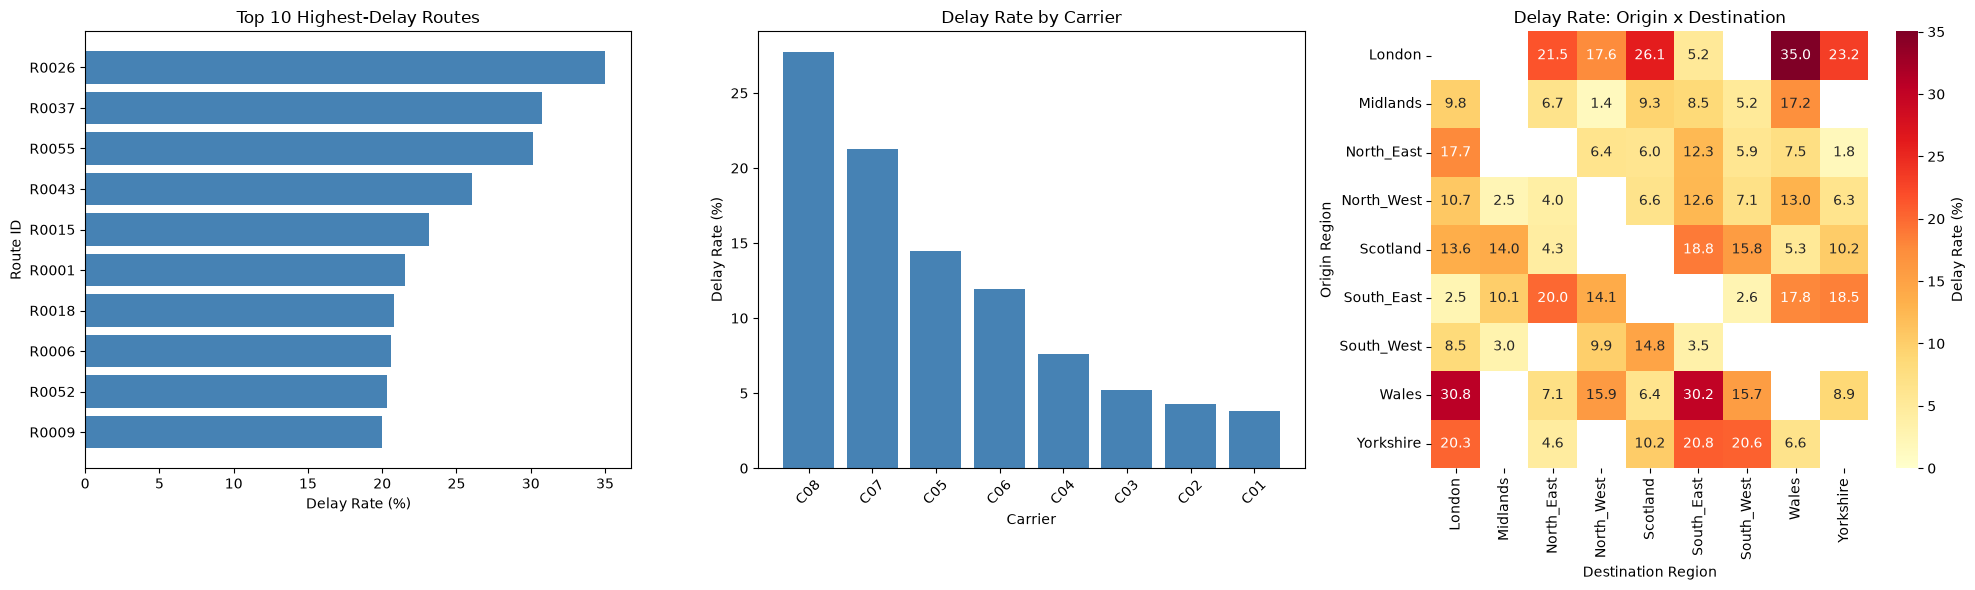

In [97]:
# *(2 marks)* Show: top 10 highest-delay routes, delay rate by carrier,
# and a heatmap of delay rate by origin x destination region.

# Your code here
df = merge.copy()

fig, ax = plt.subplots(1, 3, figsize=(20, 6))

# 1. Top 10 highest-delay routes
route_stats = (
    df.groupby('route_id')['is_delayed']
    .agg(sample_count='size', delay_rate='mean')
)

top_routes = (
    route_stats[route_stats['sample_count'] >= 20]
    .nlargest(10, 'delay_rate')
    .sort_values('delay_rate')
)

ax[0].barh(
    top_routes.index,
    top_routes['delay_rate'] * 100,
    color='steelblue'
)
ax[0].set(
    title='Top 10 Highest-Delay Routes',
    xlabel='Delay Rate (%)',
    ylabel='Route ID'
)

# 2. Delay rate by carrier
carrier_stats = (
    df.groupby('carrier_id')['is_delayed']
    .agg(sample_count='size', delay_rate='mean')
    .sort_values('delay_rate', ascending=False)
)

ax[1].bar(
    carrier_stats.index,
    carrier_stats['delay_rate'] * 100,
    color='steelblue'
)
ax[1].set(
    title='Delay Rate by Carrier',
    xlabel='Carrier',
    ylabel='Delay Rate (%)'
)
ax[1].tick_params(axis='x', rotation=45)

# 3. Origin x Destination delay rate heatmap
region_matrix = df.pivot_table(
    index='origin_region',
    columns='dest_region',
    values='is_delayed',
    aggfunc='mean',
    observed=True
) * 100

sns.heatmap(
    region_matrix,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    vmin=0,
    ax=ax[2],
    cbar_kws={'label': 'Delay Rate (%)'}
)

ax[2].set(
    title='Delay Rate: Origin x Destination',
    xlabel='Destination Region',
    ylabel='Origin Region'
)

plt.tight_layout()
plt.show()

**Commentary** - Which two route/carrier combinations are riskiest? Business implication?

- `R0026`: The highest-risk route, with a delay rate of approximately 35%, followed by R0037 at around 31%.
- `C08` and `C07`: The riskiest carriers, with delay rates of approximately 27.7% and 21.3%, respectively.
- Business implication: SwiftRoute should prioritise monitoring these high-risk routes and consider assigning more reliable carriers, rerouting shipments, or taking proactive measures to reduce delays and SLA penalties.

---
# SECTION 4 - Cleaning & Joining the Data *(12 marks)*

In [98]:
# *(2 marks)* 4.1 - Remove duplicate shipments. Keep first occurrence.

# Your code here
before = len(shipments)
print("Before removing duplicates:", before)

cols = shipments.columns.drop('shipment_id')

shipments = shipments.drop_duplicates(
    subset=cols, keep='first'
)
print(f"Removed {before - len(shipments)} duplicate shipments")
shipments

Before removing duplicates: 10025
Removed 25 duplicate shipments


,shipment_id,pickup_date,origin_region,dest_region,service_tier,carrier_id,route_id,weight_kg,volume_cm3,declared_value,is_business,is_delayed
0,SH0000001,2025-09-26,London,North_West,economy,C03,R0038,11.54,9427,5.44,0,0
1,SH0000002,2024-12-09,North_West,North_East,standard,C01,R0044,9.26,9864,7.48,1,0
2,SH0000003,2025-11-15,South_East,South_West,express,C05,R0013,0.43,96,37.44,0,0
3,SH0000004,2025-06-12,South_East,North_East,express,C08,R0009,8.84,6541,141.25,0,1
4,SH0000005,2026-03-21,Yorkshire,Scotland,standard,C04,R0010,11.10,4959,148.71,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
9995,SH0009996,2024-07-17,Scotland,North_East,standard,C08,R0054,2.61,615,62.55,1,0
9996,SH0009997,2026-05-14,North_West,Wales,economy,C08,R0020,1.57,382,62.65,1,1
9997,SH0009998,2024-11-15,South_West,London,express,C02,R0022,29.47,31952,45.93,0,1
9998,SH0009999,2024-10-20,South_East,North_East,express,C08,R0009,7.87,8423,123.60,1,0


In [99]:
# *(4 marks)* 4.2 - Join routes and carriers to shipments.
# Bring in: distance_km, n_depot_hops, historical_delay_rate, avg_transit_days
# from routes; reliability_score, capacity_utilisation from carriers.

# Your code here
merge = shipments.merge(
    routes[[
        'route_id', 'distance_km', 'n_depot_hops',
        'historical_delay_rate', 'avg_transit_days'
    ]],
    on='route_id',
    how='left'
)

merge = merge.merge(
    carriers[[
        'carrier_id', 'reliability_score', 'capacity_utilisation'
    ]],
    on='carrier_id',
    how='left'
)

merge.head()

,shipment_id,pickup_date,origin_region,dest_region,service_tier,carrier_id,route_id,weight_kg,volume_cm3,declared_value,is_business,is_delayed,distance_km,n_depot_hops,historical_delay_rate,avg_transit_days,reliability_score,capacity_utilisation
0,SH0000001,2025-09-26,London,North_West,economy,C03,R0038,11.54,9427,5.44,0,0,438,3,0.1999,2.69,0.8605,0.6675
1,SH0000002,2024-12-09,North_West,North_East,standard,C01,R0044,9.26,9864,7.48,1,0,159,1,0.0944,1.68,0.9508,0.5926
2,SH0000003,2025-11-15,South_East,South_West,express,C05,R0013,0.43,96,37.44,0,0,180,1,0.0998,1.99,0.7640,0.8150
3,SH0000004,2025-06-12,South_East,North_East,express,C08,R0009,8.84,6541,141.25,0,1,433,3,0.1825,2.61,0.5871,0.9049
4,SH0000005,2026-03-21,Yorkshire,Scotland,standard,C04,R0010,11.10,4959,148.71,0,0,153,1,0.1086,1.55,0.8332,0.7361


In [100]:
# *(6 marks)* 4.3 - Join weather events.
# For each shipment, determine the maximum weather severity affecting its
# origin region and destination region on its pickup_date.
# Hint: a shipment at row i is weather-affected at origin if there exists any
# weather event where region == origin_region AND start_date <= pickup_date <= end_date.

# Your code here
# master = ...

# Convert dates
merge['pickup_date'] = pd.to_datetime(merge['pickup_date'])

weather = weather.copy()
weather['start_date'] = pd.to_datetime(weather['start_date'])
weather['end_date'] = pd.to_datetime(weather['end_date'])

# Initialize weather severity
merge['origin_weather_severity'] = 0
merge['dest_weather_severity'] = 0

# Match weather events by region and pickup date
for event in weather.itertuples(index=False):
    in_date = merge['pickup_date'].between(
        event.start_date, event.end_date
    )

    origin = in_date & merge['origin_region'].eq(event.region)
    dest = in_date & merge['dest_region'].eq(event.region)

    merge.loc[origin, 'origin_weather_severity'] = np.maximum(
        merge.loc[origin, 'origin_weather_severity'],
        event.severity
    )

    merge.loc[dest, 'dest_weather_severity'] = np.maximum(
        merge.loc[dest, 'dest_weather_severity'],
        event.severity
    )

# Combined weather features
merge['weather_severity'] = merge[
    ['origin_weather_severity', 'dest_weather_severity']
].max(axis=1)

merge['weather_affected'] = merge['weather_severity'] > 0

master = merge.copy()
master


,shipment_id,pickup_date,origin_region,dest_region,service_tier,carrier_id,route_id,weight_kg,volume_cm3,declared_value,...,distance_km,n_depot_hops,historical_delay_rate,avg_transit_days,reliability_score,capacity_utilisation,origin_weather_severity,dest_weather_severity,weather_severity,weather_affected
0,SH0000001,2025-09-26,London,North_West,economy,C03,R0038,11.54,9427,5.44,...,438,3,0.1999,2.69,0.8605,0.6675,0,1,1,True
1,SH0000002,2024-12-09,North_West,North_East,standard,C01,R0044,9.26,9864,7.48,...,159,1,0.0944,1.68,0.9508,0.5926,0,0,0,False
2,SH0000003,2025-11-15,South_East,South_West,express,C05,R0013,0.43,96,37.44,...,180,1,0.0998,1.99,0.7640,0.8150,0,0,0,False
3,SH0000004,2025-06-12,South_East,North_East,express,C08,R0009,8.84,6541,141.25,...,433,3,0.1825,2.61,0.5871,0.9049,3,0,3,True
4,SH0000005,2026-03-21,Yorkshire,Scotland,standard,C04,R0010,11.10,4959,148.71,...,153,1,0.1086,1.55,0.8332,0.7361,0,0,0,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,SH0009996,2024-07-17,Scotland,North_East,standard,C08,R0054,2.61,615,62.55,...,211,2,0.0979,1.84,0.5871,0.9049,0,0,0,False
9996,SH0009997,2026-05-14,North_West,Wales,economy,C08,R0020,1.57,382,62.65,...,367,2,0.1906,2.57,0.5871,0.9049,1,0,1,True
9997,SH0009998,2024-11-15,South_West,London,express,C02,R0022,29.47,31952,45.93,...,275,2,0.1626,2.33,0.9049,0.6838,0,0,0,False
9998,SH0009999,2024-10-20,South_East,North_East,express,C08,R0009,7.87,8423,123.60,...,433,3,0.1825,2.61,0.5871,0.9049,0,0,0,False


---
# SECTION 5 - Creating New Features *(15 marks)*

In [102]:

# *(9 marks)* Create at least 5 new features. Comment each with its rationale.
#
# Suggested directions:
# - weather_affected: binary flag - any weather at origin OR destination
# - weather_both_ends: both origin AND destination affected
# - is_winter: pickup in Nov-Feb (higher disruption risk)
# - volume_to_weight: proxy for irregular/awkward parcels
# - carrier_route_risk: carrier reliability * route historical delay rate
# - day_of_week: Monday/Friday shipments may face different delays
# - is_cross_region: same vs different region (local vs long-haul)

# Your code here
master['weather_affected'] = (master.weather_severity > 0).astype(int)  # weather exposure
master['weather_both_ends'] = (
    (master['origin_weather_severity'] > 0) &
    (master['dest_weather_severity'] > 0)
).astype(int)
master['is_winter'] = (
    master['pickup_date'].dt.month.isin([ 12, 1])
).astype(int)
master['volume_to_weight'] = (
    master['volume_cm3'] /
    master['weight_kg'].replace(0, np.nan)
)
master['carrier_route_risk'] = (1 - master.reliability_score) * master.historical_delay_rate  # carrier and route
master['pickup_weekday'] = master.pickup_date.dt.dayofweek  # staffing/dispatch patterns
master['is_weekend'] = (master.pickup_weekday >= 5).astype(int)  # weekend operations
master['hops_per_100km'] = 100 * master.n_depot_hops / master.distance_km.replace(0, np.nan)  # transfer intensity
master['transit_pace'] = master.distance_km / master.avg_transit_days.replace(0, np.nan)  # required km/day
master['weather_route_risk'] = master.weather_severity * master.historical_delay_rate  # combined hazards

service_tier_map = {
    'economy': 0,
    'standard': 1,
    'express': 2
}
master['service_tier_encoded'] = master['service_tier'].map(service_tier_map)
master.drop(['service_tier'], axis=1, inplace=True)

new_features = ['weather_both_ends','is_winter','pickup_weekday', 'is_weekend', 'weather_affected',
                'hops_per_100km', 'transit_pace', 'weather_route_risk',
                'carrier_route_risk','volume_to_weight','service_tier_encoded']
master[new_features] = master[new_features]
print(f'{len(new_features)} engineered features')
display(master[new_features].head())



11 engineered features


,weather_both_ends,is_winter,pickup_weekday,is_weekend,weather_affected,hops_per_100km,transit_pace,weather_route_risk,carrier_route_risk,volume_to_weight,service_tier_encoded
0,0,0,4,0,1,0.684932,162.825279,0.1999,0.027886,816.897747,0
1,0,1,0,0,0,0.628931,94.642857,0.0000,0.004644,1065.226782,1
2,0,0,5,1,0,0.555556,90.452261,0.0000,0.023553,223.255814,2
3,0,0,3,0,1,0.692841,165.900383,0.5475,0.075354,739.932127,2
4,0,0,5,1,0,0.653595,98.709677,0.0000,0.018114,446.756757,1


***(6 marks)* Explain your new features.**

For each feature, explain what it measures and why it should predict delays.


- `weather_affected`: flags any weather disruption at the origin or destination.
- `weather_both_ends`: identifies weather disruption at both ends of the shipment.
- `is_winter`: captures higher disruption risk during winter months.
- `pickup_weekday` and `is_weekend`: capture differences in staffing and dispatch patterns.
- `volume_to_weight`: identifies bulky or awkward parcels.
- `log_weight`: reduces skew in parcel weight.
- `weight_missing`: captures potentially informative missing weight records.
- `carrier_route_risk`: combines carrier unreliability with historical route delay risk.
- `hops_per_100km`: measures transfer and handling intensity.
- `transit_pace`: captures how much distance must be covered per transit day.
- `weather_route_risk`: combines weather severity with historical route risk.

---
# SECTION 6 - Training Models *(15 marks)*

In [103]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

EXCLUDE = ['shipment_id','pickup_date','origin_region','dest_region',
           'carrier_id','route_id','is_delayed']
# Add any categorical columns you haven't encoded yet

feature_cols = [c for c in master.columns if c not in EXCLUDE]
X = master[feature_cols]
y = master['is_delayed']

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print(f'Train: {len(X_train):,}  Val: {len(X_val):,}  Delay rate val: {y_val.mean():.2%}')

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results = {}

Train: 8,000  Val: 2,000  Delay rate val: 11.90%


In [110]:
# *(3 marks)* Model 1 - Logistic Regression
from sklearn.linear_model import LogisticRegression

# Your code here
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

# Logistic Regression with L2 regularization
logistic_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(
        penalty='l2',
        solver='liblinear',
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

# C controls regularization strength:
# smaller C = stronger regularization
param_grid = {
    'model__C': [0.01, 0.1, 1, 10, 100]
}

logistic_grid = GridSearchCV(
    logistic_pipeline,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1
)

logistic_grid.fit(X_train, y_train)

# Best model selected by cross-validation
logistic_model = logistic_grid.best_estimator_

# Validation probabilities
y_val_prob = logistic_model.predict_proba(X_val)[:, 1]

# Validation AUC
logistic_auc = roc_auc_score(y_val, y_val_prob)

results['Logistic Regression'] = logistic_auc

print(f'Best C: {logistic_grid.best_params_["model__C"]}')
print(f'CV AUC: {logistic_grid.best_score_:.4f}')
print(f'Validation AUC: {logistic_auc:.4f}')

Best C: 1
CV AUC: 0.8654
Validation AUC: 0.8689


***(2 marks)* Model 1 - explain your choices.**

- Why LR for delay prediction?
- How did you handle class imbalance?
- What regularisation and why?

*Your answer here.*
- Logistic Regression is suitable for binary classification because the target `is_delayed` has two outcomes: delayed or not delayed. It is also simple, interpretable, and provides probability estimates for ranking shipment risk.

- Stratified train-test splitting and Stratified K-Fold cross-validation were used to preserve the delay proportion across datasets.

- L2 regularisation was used to reduce overfitting and control large coefficients. The regularisation strength (`C`) was selected using cross-validation based on ROC-AUC.

In [113]:
# *(3 marks)* Model 2 - Random Forest or LightGBM

# Your code here
from sklearn.ensemble import RandomForestClassifier


rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight='balanced',
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_cv_scores = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)

rf_model.fit(X_train, y_train)
rf_val_prob = rf_model.predict_proba(X_val)[:, 1]
rf_auc = roc_auc_score(y_val, rf_val_prob)

results['Random Forest'] = rf_auc

print(f'CV AUC: {rf_cv_scores.mean():.4f} ± {rf_cv_scores.std():.4f}')
print(f'Validation AUC: {rf_auc:.4f}')

CV AUC: 0.8455 ± 0.0142
Validation AUC: 0.8485


***(2 marks)* Model 2 - explain your choices.**

*Your answer here.*

In [114]:
# *(2 marks)* Compare models. Print CV AUC, Val AUC, overfit gap.

# Your code here

# Model comparison
model_comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'CV AUC': [
        logistic_grid.best_score_,
        rf_cv_scores.mean()
    ],
    'Val AUC': [
        logistic_auc,
        rf_auc
    ]
})

# Overfit gap: difference between validation and CV performance
model_comparison['Overfit Gap'] = (
    model_comparison['Val AUC'] - model_comparison['CV AUC']
).abs()

display(model_comparison)

# Select best model based on validation AUC
if logistic_auc >= rf_auc:
    best_model = logistic_model
    best_prob = y_val_prob
    best_model_name = 'Logistic Regression'
else:
    best_model = rf_pipeline
    best_prob = rf_val_prob
    best_model_name = 'Random Forest'

print(f'Best model: {best_model_name}')

,Model,CV AUC,Val AUC,Overfit Gap
0,Logistic Regression,0.865424,0.868923,0.003499
1,Random Forest,0.845541,0.848477,0.002936


Best model: Logistic Regression


***(3 marks)* Which model did you choose and why?**

*Your answer here.*

**Logistic Regression was selected as the final model** because it achieved the highest performance, with a CV AUC of **0.865** and a validation AUC of **0.869**, compared with **0.846** and **0.848** for Random Forest. Its overfit gap was also very small (**0.0035**), indicating stable performance between cross-validation and validation data. Therefore, Logistic Regression provided the best balance of predictive accuracy, generalisation, and interpretability.

---
# SECTION 7 - Evaluating Your Model *(8 marks)*

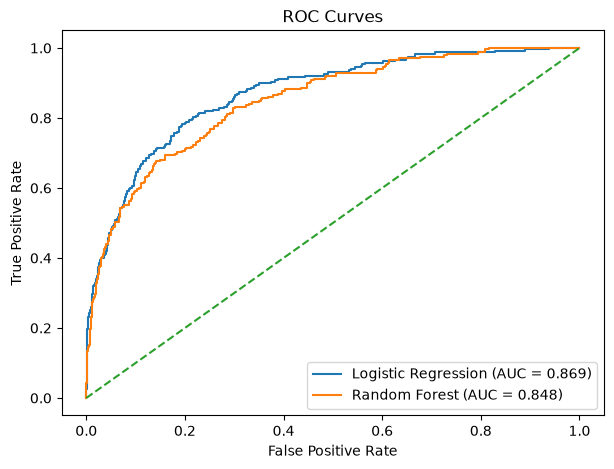

In [116]:
# *(8 marks)* Produce:
# 1. ROC curves for all models
# 2. Score distribution by delay=0 vs delay=1
# 3. Feature importance / coefficients (top 15)

# Your code here
from sklearn.metrics import roc_curve, auc
plt.figure(figsize=(7, 5))

models_prob = {
    'Logistic Regression': y_val_prob,
    'Random Forest': rf_val_prob
}

for name, prob in models_prob.items():
    fpr, tpr, _ = roc_curve(y_val, prob)
    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f'{name} (AUC = {roc_auc:.3f})'
    )

plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves')
plt.legend()
plt.show()




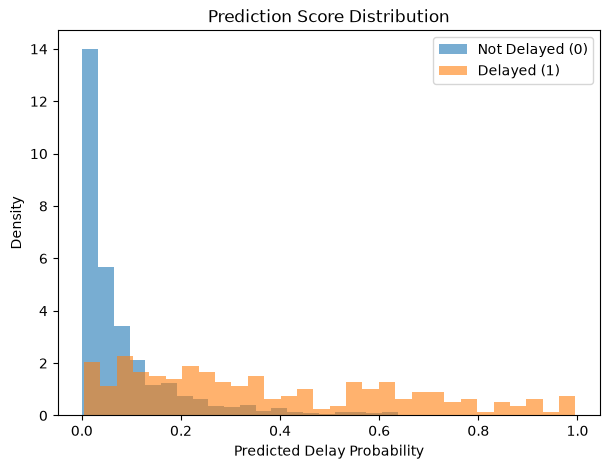

In [117]:
plt.figure(figsize=(7, 5))

plt.hist(
    y_val_prob[y_val == 0],
    bins=30,
    alpha=0.6,
    density=True,
    label='Not Delayed (0)'
)

plt.hist(
    y_val_prob[y_val == 1],
    bins=30,
    alpha=0.6,
    density=True,
    label='Delayed (1)'
)

plt.xlabel('Predicted Delay Probability')
plt.ylabel('Density')
plt.title('Prediction Score Distribution')
plt.legend()
plt.show()


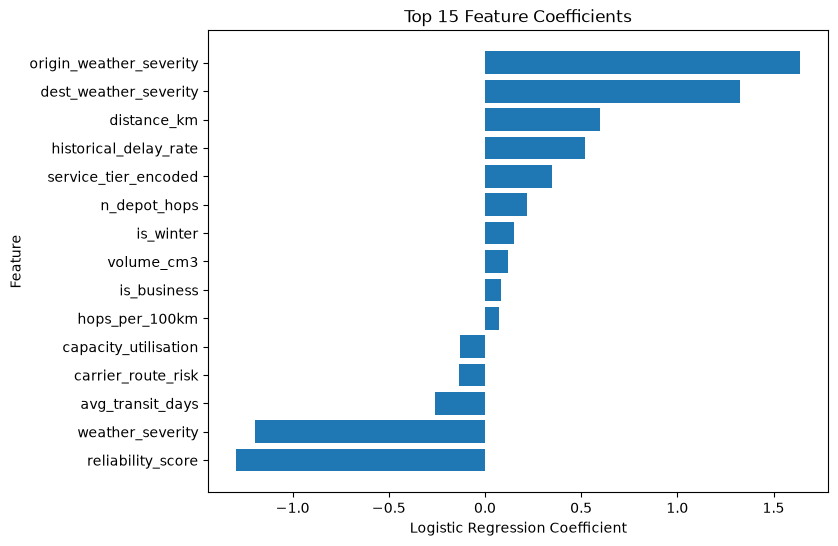

,Feature,Coefficient,Abs_Coefficient
10,origin_weather_severity,1.637665,1.637665
11,dest_weather_severity,1.325690,1.325690
8,reliability_score,-1.292368,1.292368
12,weather_severity,-1.193367,1.193367
4,distance_km,0.597852,0.597852
6,historical_delay_rate,0.520913,0.520913
23,service_tier_encoded,0.348797,0.348797
7,avg_transit_days,-0.259658,0.259658
5,n_depot_hops,0.217662,0.217662
15,is_winter,0.152405,0.152405


In [118]:
lr_estimator = logistic_model.named_steps['model']

coef_df = pd.DataFrame({
    'Feature': feature_cols,
    'Coefficient': lr_estimator.coef_[0]
})

# Absolute coefficient used to rank feature importance
coef_df['Abs_Coefficient'] = coef_df['Coefficient'].abs()

top15 = (
    coef_df
    .sort_values('Abs_Coefficient', ascending=False)
    .head(15)
    .sort_values('Coefficient')
)

plt.figure(figsize=(8, 6))

plt.barh(
    top15['Feature'],
    top15['Coefficient']
)

plt.xlabel('Logistic Regression Coefficient')
plt.ylabel('Feature')
plt.title('Top 15 Feature Coefficients')
plt.show()

display(
    coef_df
    .sort_values('Abs_Coefficient', ascending=False)
    .head(15)
)

**Interpret your diagnostics.**

*Your answer here.*
- **ROC:** Logistic Regression performs better than Random Forest (**AUC 0.869 vs 0.848**).
- **Score distribution:** Delayed shipments generally receive higher predicted probabilities, though some overlap remains.
- **Positive predictors:** Weather severity, distance, and historical route delay rate increase delay risk.
- **Negative predictor:** Higher carrier reliability reduces delay risk.
- **Overall:** The model captures meaningful operational patterns and separates delayed vs non-delayed shipments reasonably well.

---
# SECTION 8 - Business Impact *(12 marks)*

In [119]:
# *(7 marks)* Compute the delay capture rate at 15% intervention.
#
# Delay capture rate = (# actual delays in top-15% flagged) / (# total actual delays)
#
# Compare:
#   (a) Random 15% policy
#   (b) Model top-15% policy
#
# Also compute: SLA penalty avoided.
# Assume each avoided delay saves £45 in SLA penalties + handling costs.

# Your code here
# Business evaluation at 15% intervention

val_results = pd.DataFrame({
    'actual': y_val.values,
    'risk_score': best_prob
})

# Number of shipments to flag
top_n = int(len(val_results) * 0.15)

# Sort by predicted risk
val_results = val_results.sort_values(
    'risk_score',
    ascending=False
)

# Top 15% flagged by model
flagged = val_results.head(top_n)

# Total actual delays
total_delays = val_results['actual'].sum()

# Delays captured by model
model_delays_captured = flagged['actual'].sum()

# Delay capture rate
model_capture_rate = model_delays_captured / total_delays

# Random 15% policy expected capture rate
random_capture_rate = 0.15

# SLA penalty avoided
saving_per_delay = 45

model_penalty_avoided = (
    model_delays_captured * saving_per_delay
)

random_expected_delays = (
    total_delays * random_capture_rate
)

random_penalty_avoided = (
    random_expected_delays * saving_per_delay
)

print(f'Total validation shipments: {len(val_results):,}')
print(f'Top 15% flagged: {top_n:,}')
print(f'Total actual delays: {int(total_delays):,}')
print()

print(f'Random 15% capture rate: {random_capture_rate:.2%}')
print(f'Model top-15% capture rate: {model_capture_rate:.2%}')
print()

print(f'Random policy expected penalty avoided: £{random_penalty_avoided:,.2f}')
print(f'Model policy penalty avoided: £{model_penalty_avoided:,.2f}')
print(
    f'Additional saving from model: '
    f'£{model_penalty_avoided - random_penalty_avoided:,.2f}'
)

Total validation shipments: 2,000
Top 15% flagged: 300
Total actual delays: 238

Random 15% capture rate: 15.00%
Model top-15% capture rate: 60.08%

Random policy expected penalty avoided: £1,606.50
Model policy penalty avoided: £6,435.00
Additional saving from model: £4,828.50


***(5 marks)* What is the business impact?**

Explain in plain language the value of flagging high-risk shipments vs random selection.
What would you recommend to SwiftRoute's Operations team?

*Your answer here.*
- **Model targeting is much more effective than random selection:** flagging the top 15% highest-risk shipments captures **60.08% of all delays**, compared with only **15%** under random selection.
- This would avoid about **£6,435** in SLA penalties and handling costs on the validation set, around **£4,828.50 more** than random targeting.
- I recommend SwiftRoute use the model to prioritise the highest-risk 15% of shipments for actions such as re-routing, service upgrades, or customer pre-alerts.
- The model should be monitored and retrained regularly as carrier, route, and weather patterns change.

---
## 8.2 - Save Your Model for Deployment

In [120]:
import joblib

joblib.dump(best_model, 'model.pkl')
print('Model saved to model.pkl')

Model saved to model.pkl


---
# SECTION 9 - Monitoring for Drift in Production *(5 marks)*

**9.1** *(2 marks)* Propose how you would detect **input drift** on the live shipment stream. Which features are most likely to drift and what tests would you use?

*Your answer here.*

- Monitor live feature distributions against the training data.
- Features most likely to drift include `weather_severity`, `capacity_utilisation`, `historical_delay_rate`, `distance_km`, and `service_tier_encoded`.
- Use **PSI** for distribution changes, **KS tests** for numeric features, and category proportion checks for categorical variables.
- Investigate features when drift exceeds a predefined threshold.

---

**9.2** *(3 marks)* Propose how you would detect **target drift** - i.e. the actual delay rate changing in ways the model no longer predicts correctly. What would trigger retraining?

*Your answer here.*

- Compare the actual delay rate with the model’s predicted delay rate over time.
- Also monitor AUC, calibration, and delay capture rate at the top 15%.
- Retraining should be triggered if the actual delay rate changes substantially, model AUC falls below the acceptable level, or the top-15% capture rate declines consistently.
- Retraining could also be scheduled periodically to incorporate recent carrier, route, and weather patterns.

---
# EXTENSION *(10 marks)*

Attempt **both** tasks (5 marks each).

**E1** *(5 marks)* **Route-level analysis**: cluster routes by risk profile. Can you identify systematic weaknesses in SwiftRoute's network?

**E2** *(5 marks)* **SHAP**: for the top 10 highest-risk shipments in the validation set, use SHAP to explain exactly which factors are driving each prediction.

,routes,avg_shipments,avg_delay_rate,avg_historical_delay,avg_distance_km,avg_depot_hops,avg_transit_days
cluster,,,,,,,
0,22,166.863636,0.202736,0.244268,531.909091,3.000000,3.003636
2,21,164.761905,0.089394,0.154590,303.809524,2.000000,2.279048
1,17,168.764706,0.046685,0.103500,164.000000,1.058824,1.835294


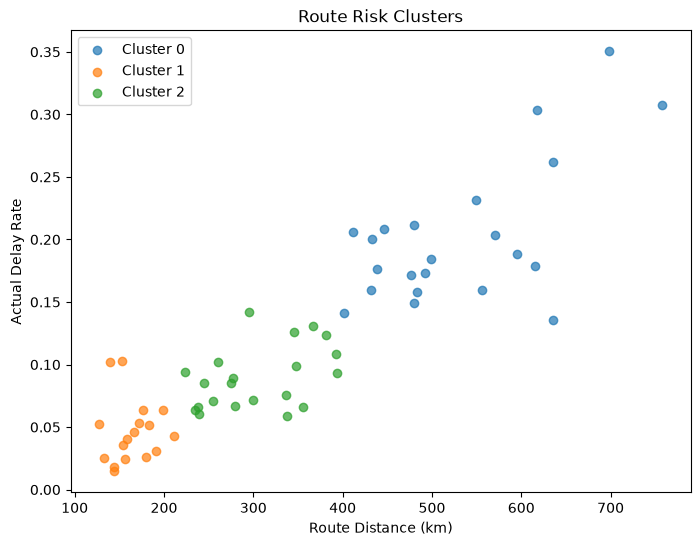

Highest-risk cluster: 0


,route_id,shipment_count,actual_delay_rate,distance_km,n_depot_hops,historical_delay_rate,avg_transit_days,cluster
25,R0026,177,0.350282,698,3,0.3311,3.64,0
36,R0037,156,0.307692,758,3,0.2793,3.80,0
54,R0055,178,0.303371,618,3,0.3517,3.47,0
42,R0043,164,0.262195,636,3,0.2880,3.15,0
14,R0015,177,0.231638,549,3,0.2864,3.05,0
0,R0001,194,0.211340,480,3,0.2471,2.92,0
17,R0018,149,0.208054,446,3,0.2579,2.65,0
5,R0006,165,0.206061,412,3,0.2496,2.67,0
51,R0052,172,0.203488,570,3,0.2562,2.92,0
8,R0009,160,0.200000,433,3,0.1825,2.61,0


In [127]:
# E1
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Aggregate shipment outcomes by route
route_perf = (
    master.groupby('route_id')
    .agg(
        shipment_count=('is_delayed', 'size'),
        actual_delay_rate=('is_delayed', 'mean'),
        distance_km=('distance_km', 'first'),
        n_depot_hops=('n_depot_hops', 'first'),
        historical_delay_rate=('historical_delay_rate', 'first'),
        avg_transit_days=('avg_transit_days', 'first')
    )
    .reset_index()
)

# Features used to describe route risk profile
cluster_features = [
    'distance_km',
    'n_depot_hops',
    'historical_delay_rate',
    'avg_transit_days',
    'actual_delay_rate'
]

X_route = route_perf[cluster_features].copy()

# Handle missing values
X_route = X_route.fillna(X_route.median())

# Scale features before KMeans
scaler = StandardScaler()
X_route_scaled = scaler.fit_transform(X_route)

# Cluster routes into 3 risk profiles
kmeans = KMeans(
    n_clusters=3,
    random_state=RANDOM_STATE,
    n_init=10
)

route_perf['cluster'] = kmeans.fit_predict(X_route_scaled)

cluster_summary = (
    route_perf.groupby('cluster')
    .agg(
        routes=('route_id', 'count'),
        avg_shipments=('shipment_count', 'mean'),
        avg_delay_rate=('actual_delay_rate', 'mean'),
        avg_historical_delay=('historical_delay_rate', 'mean'),
        avg_distance_km=('distance_km', 'mean'),
        avg_depot_hops=('n_depot_hops', 'mean'),
        avg_transit_days=('avg_transit_days', 'mean')
    )
    .sort_values('avg_delay_rate', ascending=False)
)

display(cluster_summary)



plt.figure(figsize=(8, 6))

for cluster in sorted(route_perf['cluster'].unique()):
    data = route_perf[route_perf['cluster'] == cluster]

    plt.scatter(
        data['distance_km'],
        data['actual_delay_rate'],
        alpha=0.7,
        label=f'Cluster {cluster}'
    )

plt.xlabel('Route Distance (km)')
plt.ylabel('Actual Delay Rate')
plt.title('Route Risk Clusters')
plt.legend()
plt.show()


high_risk_cluster = cluster_summary['avg_delay_rate'].idxmax()
high_risk_routes = (
    route_perf[route_perf['cluster'] == high_risk_cluster]
    .sort_values('actual_delay_rate', ascending=False)
)

print(f'Highest-risk cluster: {high_risk_cluster}')
display(high_risk_routes.head(10))

- Longer routes show consistently higher delay rates, suggesting **distance is a major network weakness**.
- Cluster 0 contains the longest routes and the highest delay rates, often above **15–30%**.
- Short routes in Cluster 1 generally perform much better, with mostly low delay rates.
- Cluster 2 sits between the two, indicating moderate risk for medium-distance routes.
- Overall, SwiftRoute appears weakest on **long routes**, likely due to greater operational complexity and more opportunities for disruption.


Shipment 1 | Predicted delay risk: 99.59%


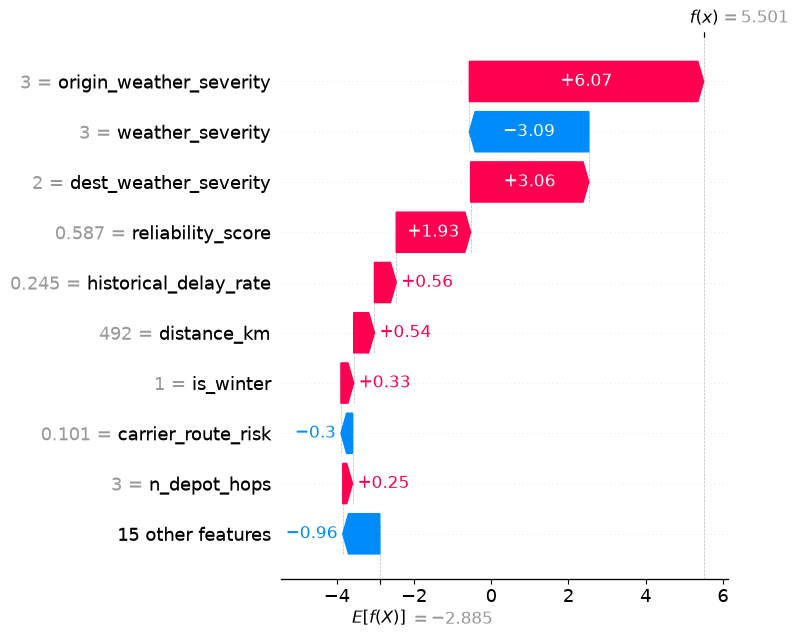


Shipment 2 | Predicted delay risk: 98.80%


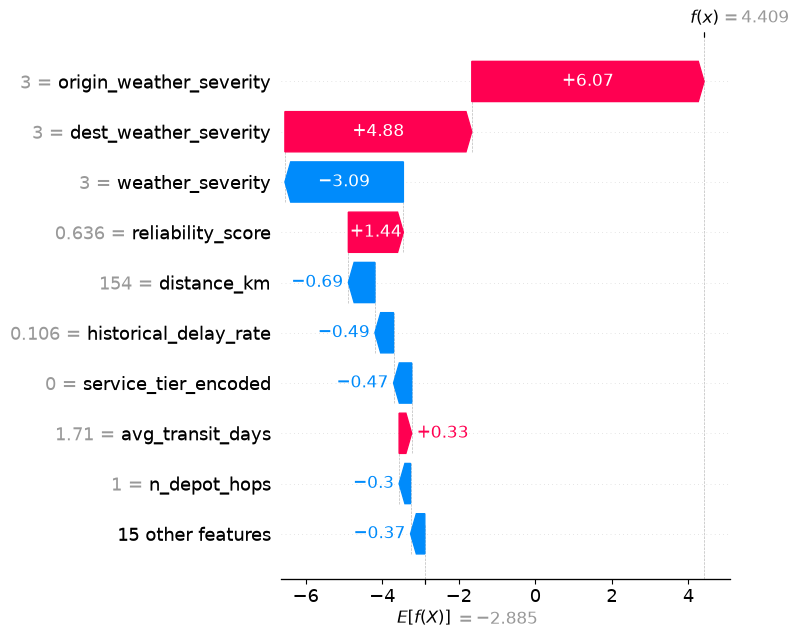


Shipment 3 | Predicted delay risk: 98.66%


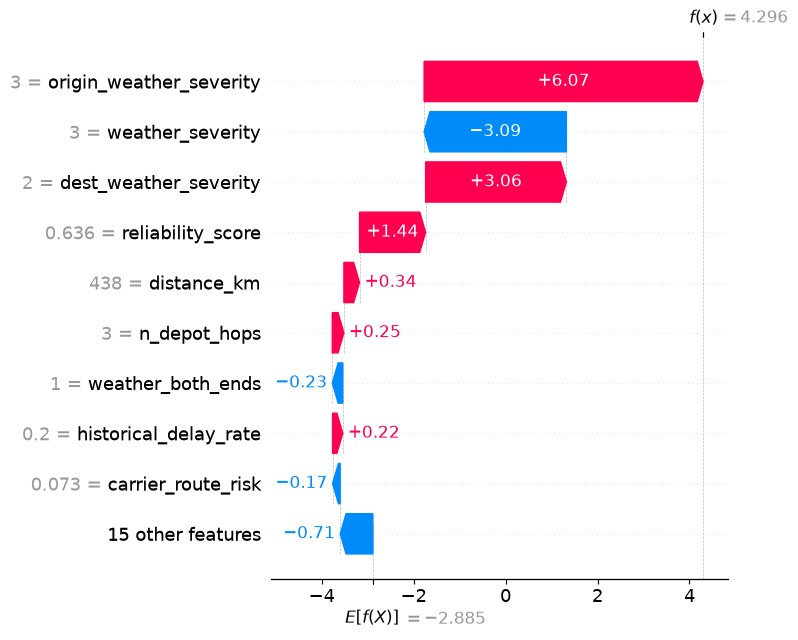


Shipment 4 | Predicted delay risk: 98.53%


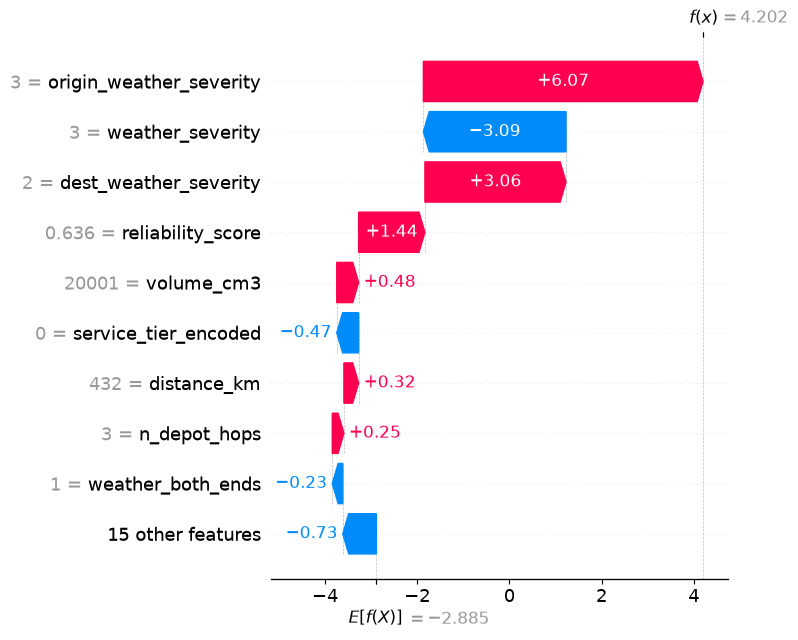


Shipment 5 | Predicted delay risk: 97.76%


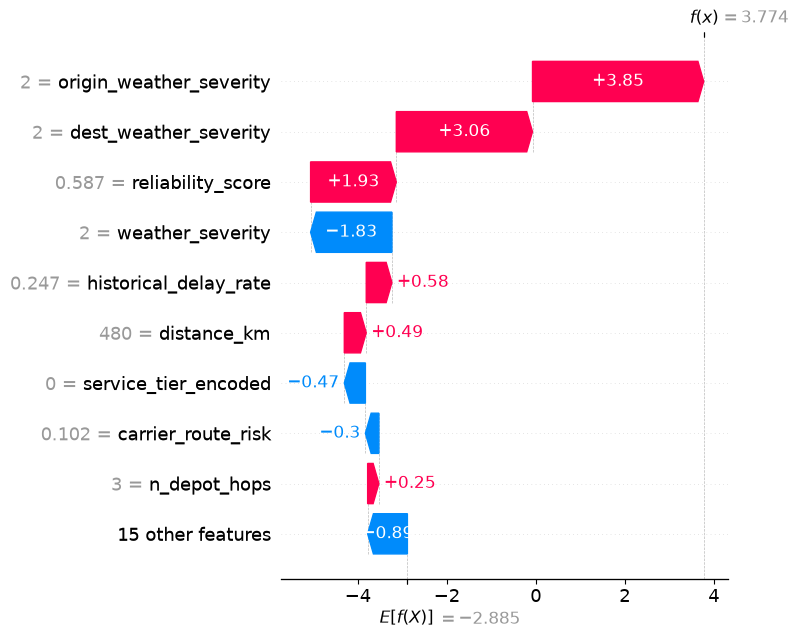


Shipment 6 | Predicted delay risk: 97.05%


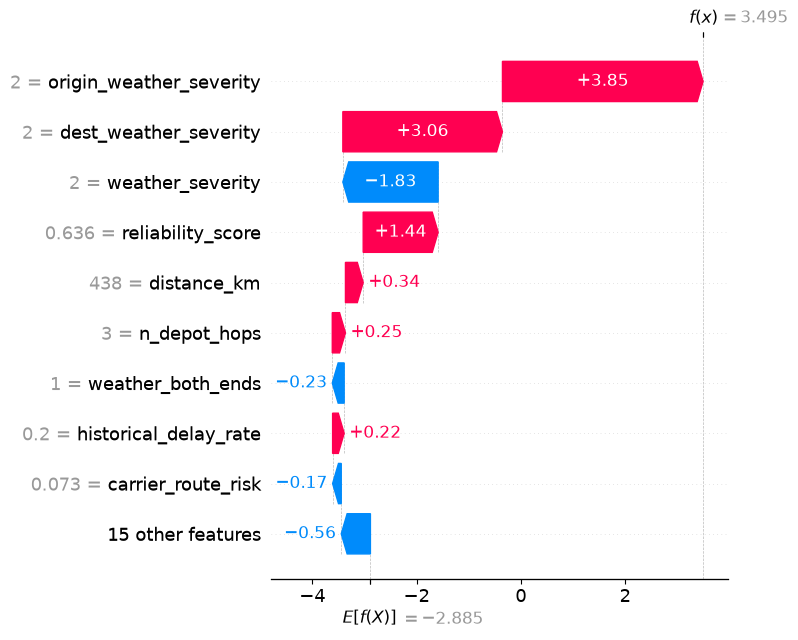


Shipment 7 | Predicted delay risk: 95.53%


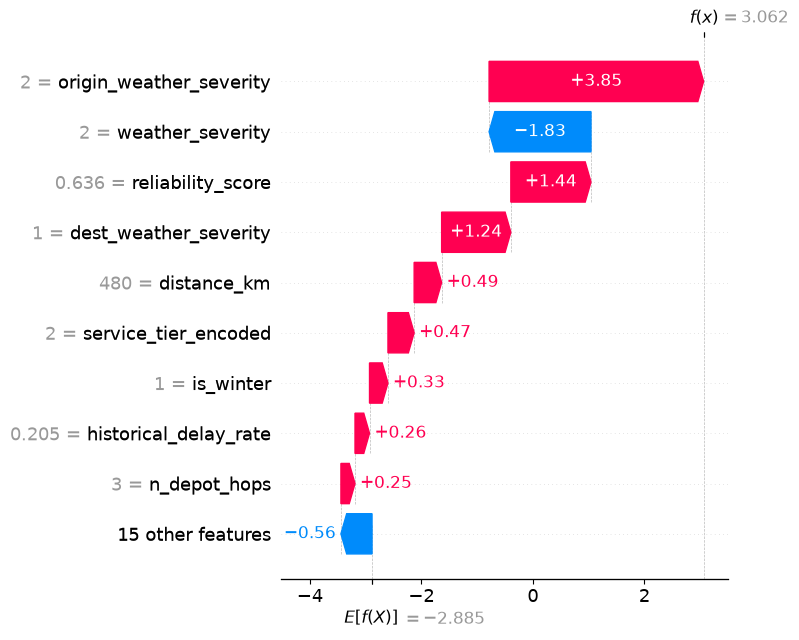


Shipment 8 | Predicted delay risk: 94.33%


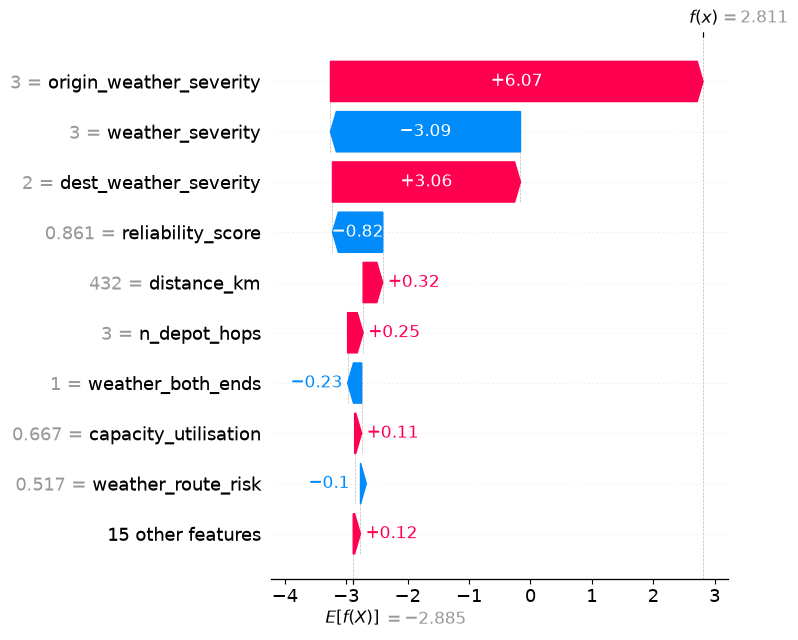


Shipment 9 | Predicted delay risk: 92.87%


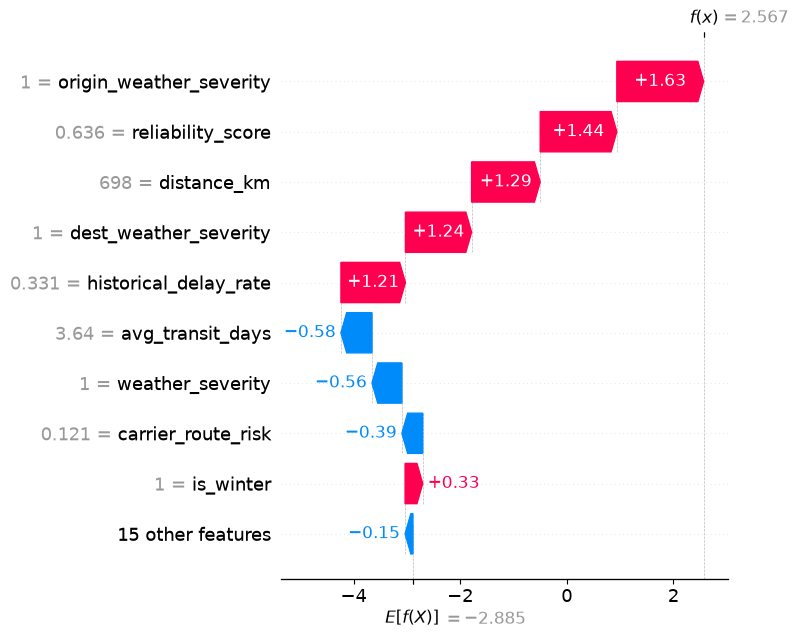


Shipment 10 | Predicted delay risk: 91.26%


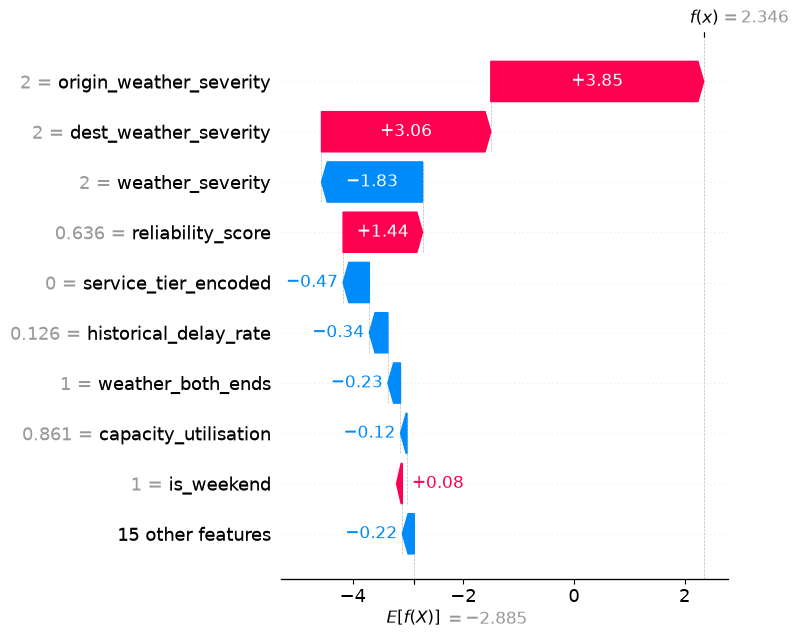

In [131]:
# E2

import shap


# Top 10 highest-risk validation shipments
top10_idx = np.argsort(best_prob)[-10:][::-1]

X_top10 = X_val.iloc[top10_idx].copy()
top10_prob = best_prob[top10_idx]

# Extract fitted pipeline components
imputer = logistic_model.named_steps['imputer']
scaler = logistic_model.named_steps['scaler']
lr_model = logistic_model.named_steps['model']

# Apply preprocessing
X_val_imputed = imputer.transform(X_val)
X_val_scaled = scaler.transform(X_val_imputed)

X_top10_imputed = imputer.transform(X_top10)
X_top10_scaled = scaler.transform(X_top10_imputed)

# Background mean in scaled feature space
background_mean = X_val_scaled.mean(axis=0)

# Logistic Regression SHAP values:
shap_vals = (
    (X_top10_scaled - background_mean)
    * lr_model.coef_[0]
)
base_value = (
    lr_model.intercept_[0]
    + np.dot(background_mean, lr_model.coef_[0])
)

# Create SHAP Explanation
explanation = shap.Explanation(
    values=shap_vals,
    base_values=np.repeat(base_value, len(X_top10)),
    data=X_top10.values,
    feature_names=feature_cols
)


for i in range(10):

    print(
        f'\nShipment {i + 1} | '
        f'Predicted delay risk: {top10_prob[i]:.2%}'
    )

    plt.figure(figsize=(9, 6))

    shap.plots.waterfall(
        explanation[i],
        max_display=10,
        show=False
    )

    plt.tight_layout()
    plt.show()